## DS605: Fundamentals of Machine Learning

### Lab Assignment - 7

### Image Representation, PCA, Eigenfaces and Face Recognition

#### Name: Puranik Aryan Hitesh
#### StudentId: 202618030

Images shape: (400, 112, 92)
Labels shape: (400,)
Single image dimensions: (112, 92)


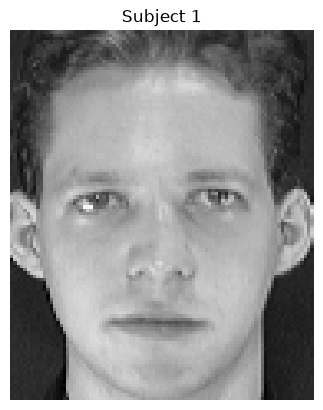

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split,StratifiedKFold
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,f1_score
from sklearn.svm import SVC

dataset_path = Path(r"D:\ml_environment\data\pca_assignment")

images = []
labels = []

for subject in range(1, 41):
    folder = dataset_path / f"s{subject}"

    for img_path in sorted(folder.glob("*.pgm")):
        img = np.array(Image.open(img_path).convert("L"))

        images.append(img)
        labels.append(subject)

images = np.array(images)
labels = np.array(labels)

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Single image dimensions:", images[0].shape)

# Display one image from loaded dataset
plt.imshow(images[0], cmap="gray")
plt.title(f"Subject {labels[0]}")
plt.axis("off")
plt.show()

* inspecting dimension and intensity of one sample image


Minimum intensity: 11
Maximum intensity: 234
Mean intensity: 128.33821816770185
Standard deviation: 53.31363778766429


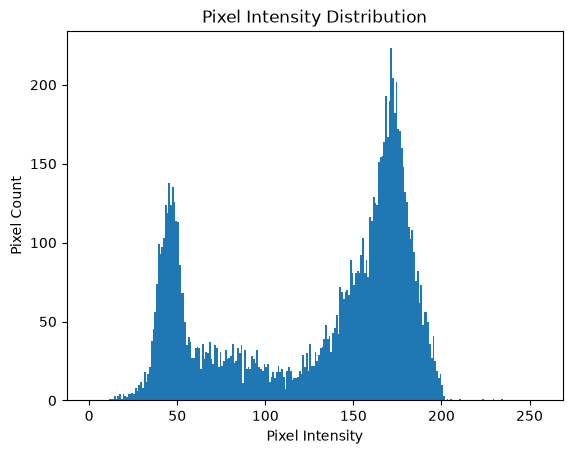

In [25]:
# Inspect intensity values of one image
img = images[0]

print("Minimum intensity:", img.min())
print("Maximum intensity:", img.max())
print("Mean intensity:", img.mean())
print("Standard deviation:", img.std())

# Plot intensity distribution
plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.xlabel("Pixel Intensity")
plt.ylabel("Pixel Count")
plt.title("Pixel Intensity Distribution")
plt.show()

*  dimensions of all images and intensity distribution 

Unique image dimensions: [[112  92]]
Minimum intensity: 0
Maximum intensity: 251
Mean intensity: 112.6312849378882
Standard deviation: 49.92474866447237


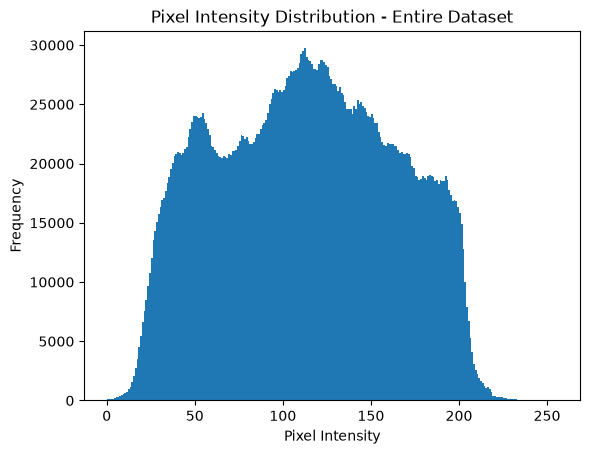

In [26]:
# Dimensions of all images
print("Unique image dimensions:", np.unique(
    [img.shape for img in images], axis=0
))

# Intensity statistics across dataset
print("Minimum intensity:", images.min())
print("Maximum intensity:", images.max())
print("Mean intensity:", images.mean())
print("Standard deviation:", images.std())

# Plot intensity distribution across all images
plt.hist(images.ravel(), bins=256, range=(0, 256))
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Pixel Intensity Distribution - Entire Dataset")
plt.show()

* flatten to 2D matrix ( label , image )

In [27]:
# Flatten all images into feature vectors
X = images.reshape(images.shape[0], -1)
y = labels

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("First image vector shape:", X[0].shape)

Feature matrix shape: (400, 10304)
Labels shape: (400,)
First image vector shape: (10304,)


#### Train-Test split


In [28]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (320, 10304)
Testing data: (80, 10304)
Training labels: (320,)
Testing labels: (80,)


### PART B

#### Compute the mean face 

Mean face shape: (10304,)


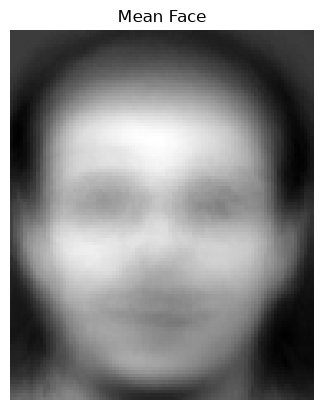

In [29]:
# Compute mean face
mean_face = np.mean(X_train, axis=0)

print("Mean face shape:", mean_face.shape)

# Reshape and visualize
plt.imshow(mean_face.reshape(112, 92), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

#### Mean Centering 

In [30]:
# Mean center training and testing data
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Centered training shape:", X_train_centered.shape)
print("Centered testing shape:", X_test_centered.shape)

# Verify mean centering
print("Mean after centering:", X_train_centered.mean())

Centered training shape: (320, 10304)
Centered testing shape: (80, 10304)
Mean after centering: 7.061294268423356e-17


#### eigenvlaues and eigenfaces with cov matrix and eigen decomp.


In [31]:
# 1. Compute smaller covariance matrix
n_samples = X_train_centered.shape[0]

G = (X_train_centered @ X_train_centered.T) / (n_samples - 1)

# 2. Eigenvalue decomposition
eigenvalues, eigenvectors = np.linalg.eigh(G)

# 3. Sort eigenvalues and eigenvectors in descending order
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

# 4. Remove zero or numerically negligible eigenvalues
valid = eigenvalues > eigenvalues[0] * 1e-12

eigenvalues = eigenvalues[valid]
eigenvectors = eigenvectors[:, valid]

# 5. Recover eigenfaces in original pixel space
eigenfaces = X_train_centered.T @ eigenvectors

# 6. Normalize eigenfaces to unit length
eigenfaces /= np.linalg.norm(eigenfaces, axis=0)

print("Gram matrix:", G.shape)
print("Eigenvalues:", eigenvalues.shape)
print("Eigenfaces:", eigenfaces.shape)

Gram matrix: (320, 320)
Eigenvalues: (319,)
Eigenfaces: (10304, 319)


#### same task with svd and comparision

In [32]:
# PCA using SVD
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)

# Principal directions and corresponding eigenvalues
svd_eigenfaces = Vt.T
svd_eigenvalues = (S ** 2) / (n_samples - 1)

print("SVD principal directions:", svd_eigenfaces.shape)

# Compare first 20 principal components
k = 20

# Compare eigenvalues
relative_error = np.abs(
    eigenvalues[:k] - svd_eigenvalues[:k]
) / eigenvalues[:k]

# Compare principal directions (ignoring sign differences)
similarity = np.abs(
    np.sum(
        eigenfaces[:, :k] * svd_eigenfaces[:, :k],
        axis=0
    )
)

print("Maximum relative eigenvalue error:", relative_error.max())
print("Minimum direction similarity:", similarity.min())

SVD principal directions: (10304, 320)
Maximum relative eigenvalue error: 3.054813345240156e-15
Minimum direction similarity: 0.9999999999999956


In [33]:
print(eigenvalues[:k])

print(svd_eigenvalues[:k])

[2840597.83002768 2076428.8868885  1108913.7662049   908967.32639212
  844133.48696141  551634.38689824  411333.39898989  372927.88103898
  304426.4179795   293977.84315501  240473.35599079  219774.21519558
  185592.19314777  173344.03991672  162101.51316966  147561.50994196
  142908.06262557  136133.84115772  118734.35401771  117003.34695578]
[2840597.83002768 2076428.88688851 1108913.7662049   908967.32639212
  844133.48696141  551634.38689824  411333.39898988  372927.88103898
  304426.4179795   293977.84315501  240473.35599079  219774.21519558
  185592.19314777  173344.03991672  162101.51316966  147561.50994196
  142908.06262557  136133.84115772  118734.35401771  117003.34695578]


#### Explained variance 

Minimum components for 90% variance: 98
Variance retained: 90.05809188922824 %


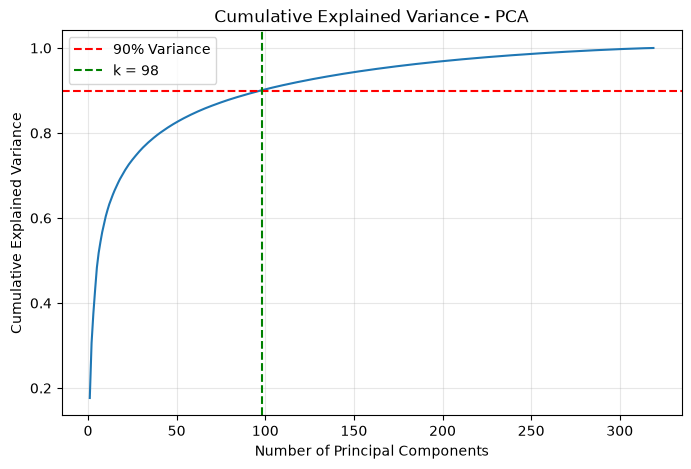

In [34]:
# Explained variance ratio
explained_variance_ratio = eigenvalues / eigenvalues.sum()

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)

# Minimum components for 90% variance
k = np.searchsorted(cumulative_variance, 0.90) + 1

print("Minimum components for 90% variance:", k)
print("Variance retained:", cumulative_variance[k - 1] * 100, "%")

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(0.90, color="red", linestyle="--", label="90% Variance")
plt.axvline(k, color="green", linestyle="--", label=f"k = {k}")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance - PCA")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### visualise eigenfaces


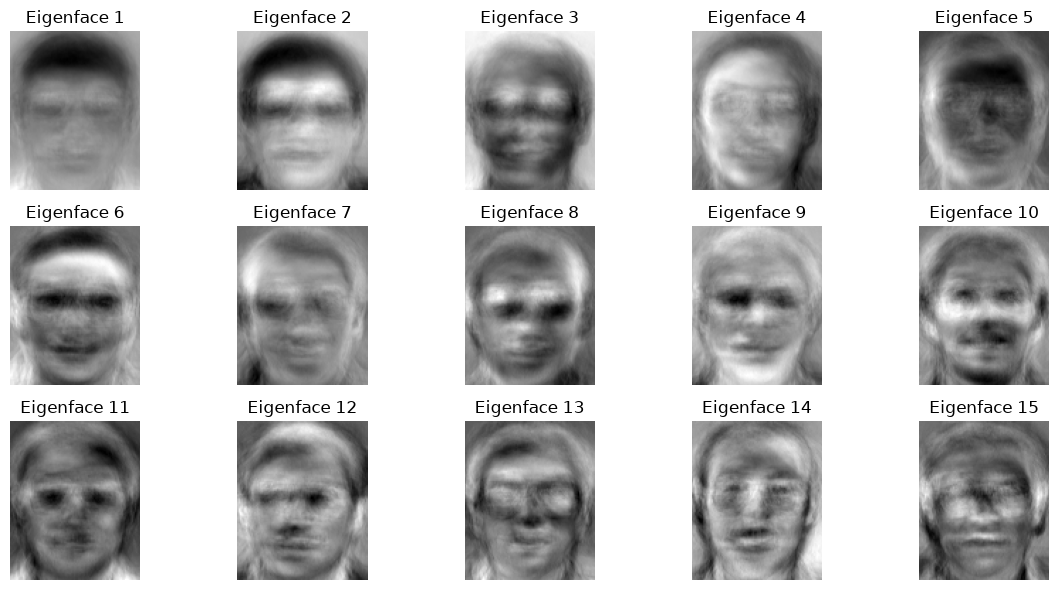

In [35]:
# Visualize the first 10 eigenfaces
fig, axes = plt.subplots(3, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    eigenface = eigenfaces[:, i].reshape(112, 92)

    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Project images to PCA space 

In [36]:
# Select first k principal components
V_k = eigenfaces[:, :k]

# Project training and testing data into PCA space
Z_train = X_train_centered @ V_k
Z_test = X_test_centered @ V_k

print("Original training shape:", X_train.shape)
print("PCA training shape:", Z_train.shape)

print("Original testing shape:", X_test.shape)
print("PCA testing shape:", Z_test.shape)

print("Dimensionality reduction:",
      f"{(1 - k / X_train.shape[1]) * 100:.2f}%")

Original training shape: (320, 10304)
PCA training shape: (320, 98)
Original testing shape: (80, 10304)
PCA testing shape: (80, 98)
Dimensionality reduction: 99.05%


#### Reconstruct faces from the PCA representation and compare the reconstructed images against the originals to evaluate reconstruction quality.

Reconstruction MSE: 334.9898829101203


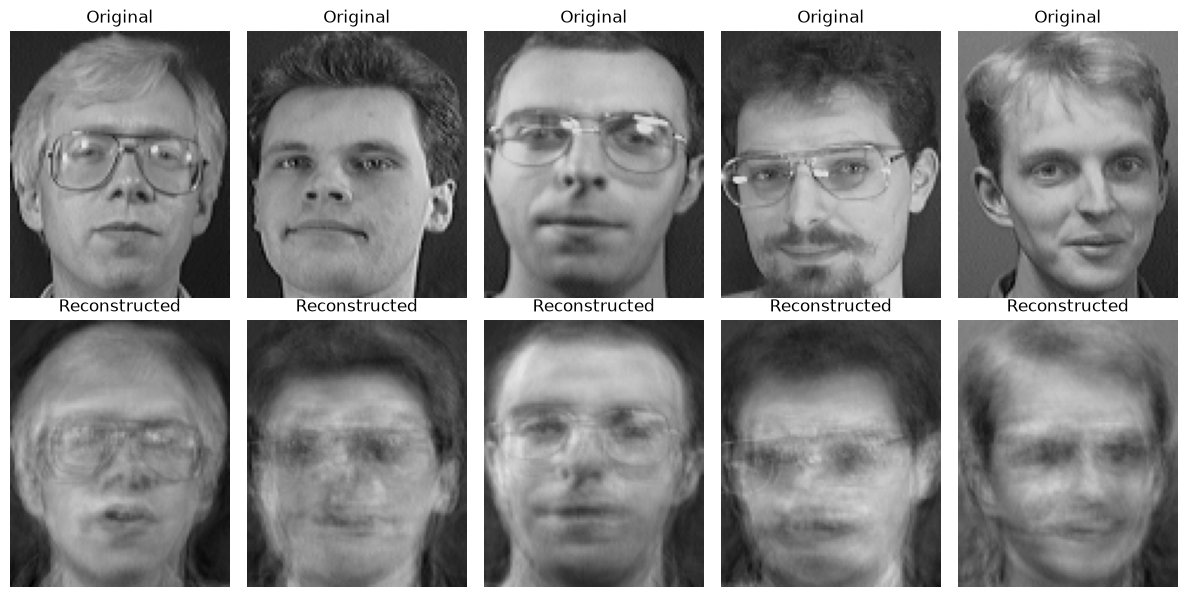

In [37]:
# Reconstruct test images from PCA space
X_reconstructed = Z_test @ V_k.T + mean_face

# Calculate reconstruction error
mse = np.mean((X_test - X_reconstructed) ** 2)

print("Reconstruction MSE:", mse)

# Compare original and reconstructed faces
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i in range(5):
    axes[0, i].imshow(X_test[i].reshape(112, 92),
                       cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(X_reconstructed[i].reshape(112, 92),
                       cmap="gray", vmin=0, vmax=255)
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### PART C


#### Face Recognition using Nearest Neighbor (Euclidean Distance)

In [38]:
# Compute Euclidean distances between test and training faces
distances = np.linalg.norm(
    Z_test[:, None, :] - Z_train[None, :, :],
    axis=2
)

# Find nearest training image for each test image
nearest_indices = np.argmin(distances, axis=1)

# Predict subject labels
y_pred_pca = y_train[nearest_indices]

print("Distance matrix shape:", distances.shape)
print("Predicted labels:", y_pred_pca[:10])
print("Actual labels:   ", y_test[:10])

Distance matrix shape: (80, 320)
Predicted labels: [ 2 36 19 17 40 24 33 20  4 35]
Actual labels:    [ 2 36 19 17 40 24 33 20  4 35]


#### Accuracy and prediction visualization

PCA Recognition Accuracy: 96.25%
Correct predictions: 77
Incorrect predictions: 3


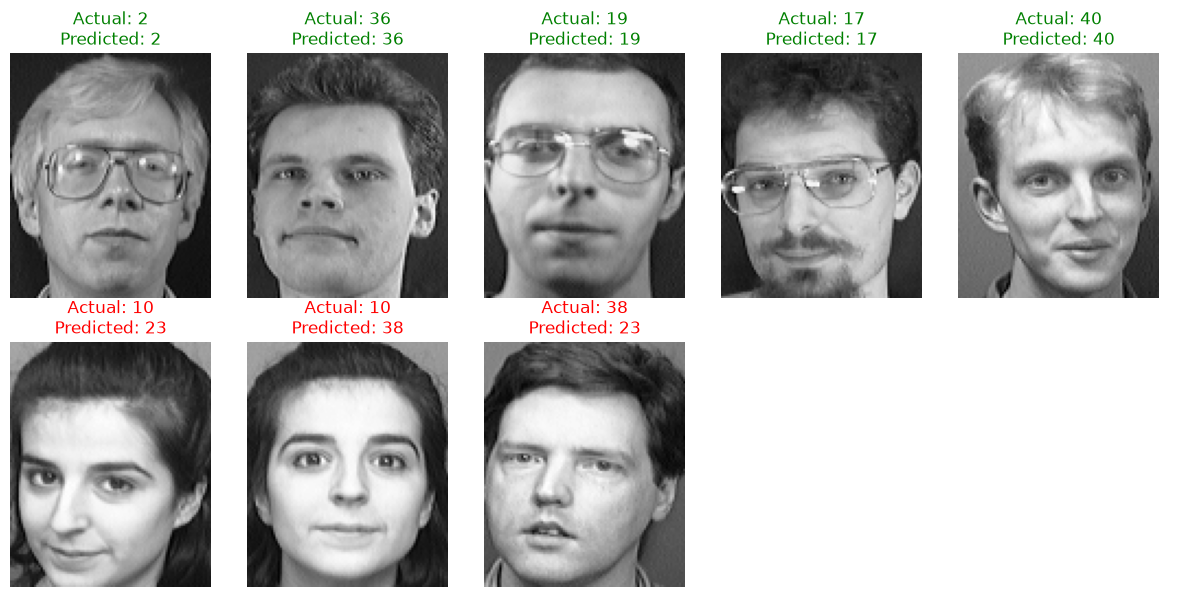

In [39]:
# Calculate recognition accuracy
accuracy = np.mean(y_pred_pca == y_test)

correct_idx = np.where(y_pred_pca == y_test)[0]
incorrect_idx = np.where(y_pred_pca != y_test)[0]
print(f"PCA Recognition Accuracy: {accuracy * 100:.2f}%")
print("Correct predictions:", len(correct_idx))
print("Incorrect predictions:", len(incorrect_idx))

# Visualize sample predictions
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for row, indices in enumerate([correct_idx, incorrect_idx]):
    for col, ax in enumerate(axes[row]):
        if col < len(indices):
            i = indices[col]

            ax.imshow(X_test[i].reshape(112, 92), cmap="gray")
            ax.set_title(
                f"Actual: {y_test[i]}\nPredicted: {y_pred_pca[i]}",
                color="green" if row == 0 else "red"
            )

        ax.axis("off")

axes[0, 0].set_ylabel("Correct", fontsize=12)
axes[1, 0].set_ylabel("Incorrect", fontsize=12)

plt.tight_layout()
plt.show()

#### Compare Raw Pixel vs PCA Face Recognition

In [40]:
# Euclidean distances using original pixel features
raw_distances = np.linalg.norm(
    X_test[:, None, :] - X_train[None, :, :],
    axis=2
)

# Find nearest neighbors
raw_nearest_indices = np.argmin(raw_distances, axis=1)

# Predict labels
y_pred_raw = y_train[raw_nearest_indices]

# Calculate accuracy
accuracy_raw = np.mean(y_pred_raw == y_test)

print(f"Raw Pixel Accuracy: {accuracy_raw * 100:.2f}%")
print(f"PCA Accuracy:       {accuracy * 100:.2f}%")

Raw Pixel Accuracy: 2.50%
PCA Accuracy:       96.25%


In [41]:


comparison = pd.DataFrame({
    "Method": ["Raw Pixels", "PCA Features"],
    "Features": [X_train.shape[1], k],
    "Accuracy (%)": [accuracy_raw * 100, accuracy * 100]
})

display(comparison)

,Method,Features,Accuracy (%)
0,Raw Pixels,10304,2.50
1,PCA Features,98,96.25


### PART D

### KNN

In [42]:


# Initialize KNN classifier
knn = KNeighborsClassifier(n_neighbors=3)

# Train using PCA features
knn.fit(Z_train, y_train)

# Predict test labels
y_pred_knn = knn.predict(Z_test)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")

KNN Accuracy: 95.00%


#### SVM

In [43]:

# Initialize SVM classifier
svm = SVC(kernel="rbf", C=1.0, gamma="scale")

# Train using PCA features
svm.fit(Z_train, y_train)

# Predict test labels
y_pred_svm = svm.predict(Z_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

SVM Accuracy: 98.75%


#### Comparision

In [44]:
comparison_ml = pd.DataFrame({
    "Classifier": ["KNN (k=3)", "SVM (RBF)"],
    "PCA Components": [k, k],
    "Accuracy (%)": [
        knn_accuracy * 100,
        svm_accuracy * 100
    ]
})

display(comparison_ml)

,Classifier,PCA Components,Accuracy (%)
0,KNN (k=3),98,95.00
1,SVM (RBF),98,98.75


#### hyperparameter tuning for svm and knn with cross validation


In [45]:


components = [20, 50 , 100, 150]
neighbors = [1, 3, 5]
C_values = [0.1, 1, 10]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = []

for train_idx, val_idx in cv.split(X_train, y_train):

    X_tr = X_train[train_idx].astype(float)
    X_val = X_train[val_idx].astype(float)
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    # Fit PCA using only the current training fold
    mu = X_tr.mean(axis=0)
    A = X_tr - mu

    G = A @ A.T
    eigvals, U = np.linalg.eigh(G)
    U = U[:, np.argsort(eigvals)[::-1]]

    V = A.T @ U[:, :max(components)]
    V /= np.linalg.norm(V, axis=0)

    # Project training and validation folds
    Z_tr = A @ V
    Z_val = (X_val - mu) @ V

    for n_components in components:
        train_features = Z_tr[:, :n_components]
        val_features = Z_val[:, :n_components]

        # KNN
        for n in neighbors:
            model = KNeighborsClassifier(n_neighbors=n)
            model.fit(train_features, y_tr)

            results.append([
                "KNN", n_components, n,
                model.score(val_features, y_val)
            ])

        # SVM
        for c in C_values:
            model = SVC(kernel="rbf", C=c, gamma="scale")
            model.fit(train_features, y_tr)

            results.append([
                "SVM", n_components, c,
                model.score(val_features, y_val)
            ])

# Average accuracy across folds
cv_results = pd.DataFrame(
    results,
    columns=["Model", "Components", "Parameter", "Accuracy"]
)

cv_summary = (
    cv_results
    .groupby(["Model", "Components", "Parameter"], as_index=False)
    ["Accuracy"].mean()
)

cv_summary["Accuracy"] *= 100

# Best configuration for each classifier
best_models = cv_summary.loc[
    cv_summary.groupby("Model")["Accuracy"].idxmax()
]

display(best_models)




,Model,Components,Parameter,Accuracy
3,KNN,50,1.0,94.374890
17,SVM,50,10.0,96.249927


#### Final training and evaluation

In [46]:
# Best configurations from cross-validation
best_knn = best_models[best_models["Model"] == "KNN"].iloc[0]
best_svm = best_models[best_models["Model"] == "SVM"].iloc[0]

# KNN
k_knn = int(best_knn["Components"])
n_neighbors = int(best_knn["Parameter"])

knn_final = KNeighborsClassifier(n_neighbors=n_neighbors)

knn_final.fit(
    X_train_centered @ eigenfaces[:, :k_knn],
    y_train
)

y_pred_knn_final = knn_final.predict(
    X_test_centered @ eigenfaces[:, :k_knn]
)

# SVM
k_svm = int(best_svm["Components"])
C = float(best_svm["Parameter"])

svm_final = SVC(kernel="rbf", C=C, gamma="scale")

svm_final.fit(
    X_train_centered @ eigenfaces[:, :k_svm],
    y_train
)

y_pred_svm_final = svm_final.predict(
    X_test_centered @ eigenfaces[:, :k_svm]
)

# Final comparison
final_results = pd.DataFrame({
    "Method": [
        "Raw Pixel 1-NN",
        "PCA 1-NN",
        "KNN (Tuned)",
        "SVM (Tuned)"
    ],
    "Features": [
        X_train.shape[1],
        k,
        k_knn,
        k_svm
    ],
    "Accuracy (%)": [
        accuracy_raw * 100,
        accuracy * 100,
        accuracy_score(y_test, y_pred_knn_final) * 100,
        accuracy_score(y_test, y_pred_svm_final) * 100
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_raw, average="macro"),
        f1_score(y_test, y_pred_pca, average="macro"),
        f1_score(y_test, y_pred_knn_final, average="macro"),
        f1_score(y_test, y_pred_svm_final, average="macro")
]

})



display(final_results.round(3))

,Method,Features,Accuracy (%),Macro F1
0,Raw Pixel 1-NN,10304,2.50,0.002
1,PCA 1-NN,98,96.25,0.954
2,KNN (Tuned),50,98.75,0.987
3,SVM (Tuned),50,98.75,0.987


#### storage comparision 


In [47]:
# Original images stored as uint8
original_bytes = X_train.astype(np.uint8).nbytes

# PCA representation stored as float32
pca_bytes = Z_train.astype(np.float32).nbytes

# Shared PCA basis and mean face
basis_bytes = V_k.astype(np.float32).nbytes
mean_bytes = mean_face.astype(np.float32).nbytes

total_pca_bytes = pca_bytes + basis_bytes + mean_bytes

print(f"Original images: {original_bytes / 1024**2:.2f} MB")
print(f"PCA coefficients: {pca_bytes / 1024**2:.2f} MB")
print(f"PCA basis + mean: {(basis_bytes + mean_bytes) / 1024**2:.2f} MB")
print(f"Total PCA storage: {total_pca_bytes / 1024**2:.2f} MB")

print(f"\nOriginal features per image: {X_train.shape[1]}")
print(f"PCA components per image: {k}")
print(f"Dimensionality reduction: {(1 - k / 10304) * 100:.2f}%")

Original images: 3.14 MB
PCA coefficients: 0.12 MB
PCA basis + mean: 3.89 MB
Total PCA storage: 4.01 MB

Original features per image: 10304
PCA components per image: 98
Dimensionality reduction: 99.05%
